> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 03 · Event-time response estimation

The rate factor is the first covariance principal component of MP1, MP2, ED2, ED3 and ED4, fitted on 39 development statements before quote exclusions. Its centre, orientation and standard-deviation scale remain fixed across dates and communication types. The quarterly-rate inputs switch from Eurodollar to SOFR in 2022 according to the source construction.

As Acosta et al. (2026) describe, several rate maturities can summarise different aspects of FOMC news. Here the factor is scaled to one development standard deviation rather than a structural unit shock. As Jordà (2005) motivates in his local-projection paper, separate horizon regressions avoid imposing a complete dynamic curve in advance. This event-level adaptation estimates conditional associations, not structurally identified impulse responses.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


In [2]:
from diffusion.statistics import pca_fit, pca_transform, ols_hc3, wild_band
from diffusion.empirical import data_for, panel, return_between
events = pd.read_csv(ROOT/'data/processed/event-register.csv')
dev = events.query("phase=='development' and event_type=='Statements'")
frozen = json.loads((ROOT/'outputs/models/surprise-pca.json').read_text())
fresh = pca_fit(dev[frozen['inputs']].to_numpy()*100)
for key in ['centre_bps','loadings','score_sd','explained_variance']:
    np.testing.assert_allclose(fresh[key],frozen[key],rtol=1e-12)
show_table(pd.DataFrame({'input':frozen['inputs'],'loading':frozen['loadings'],'development_centre_bp':frozen['centre_bps']}), 'Table N03.1. Frozen development PCA.')
print(f"Explained rate-input variance: {100*frozen['explained_variance']:.3f}%")
print(f"Unstandardised score SD: {frozen['score_sd']:.6f} bp")
equation(3)
equation(4)

input,loading,development_centre_bp
MP1,-0.016,0.146
MP2,0.127,0.086
ED2,0.502,0.660
ED3,0.597,0.718
ED4,0.613,0.654


Equation (3). Rate changes in basis points.
\mathbf{x}_e=100\,\left(\mathrm{MP1}_e,\mathrm{MP2}_e,\mathrm{ED2}_e,\mathrm{ED3}_e,\mathrm{ED4}_e\right)^{\mathsf T}
USMPD rate changes are supplied in percentage points.

Equation (4). Frozen rate-surprise factor.
z_e=\frac{\mathbf{w}^{\mathsf T}(\mathbf{x}_e-\bar{\mathbf{x}}_{\mathrm{dev}})}{s_{\mathrm{dev}}}
The loading vector, centre and scale are fitted on 39 development statements, then held fixed.

Explained rate-input variance: 91.493%
Unstandardised score SD: 8.009662 bp


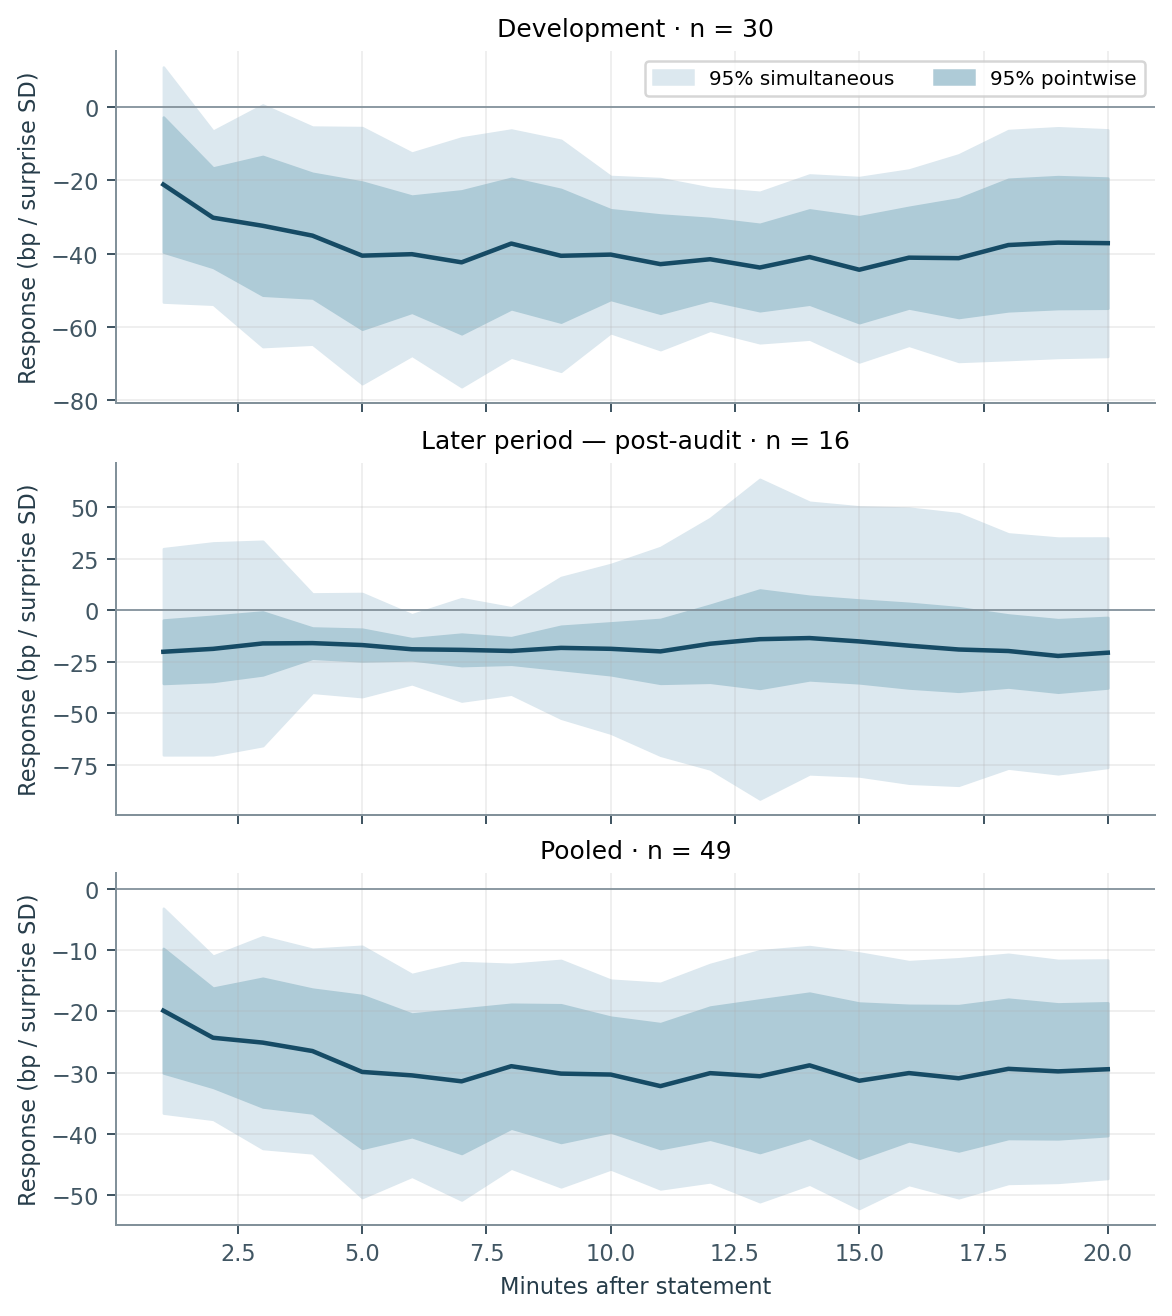

Figure 3. SPX provider-quote response to the frozen rate-surprise factor after clock correction. Pooled estimates are retrospective. Chronological transfer follows a documented source-clock repair after the original holdout had been examined; sample eligibility is reported separately.

Recomputed development curve from 30 events; late slope = 3.403792 bp/SD.


In [3]:
bars, events = data_for(['development'])
x,y,meta,prices = panel(bars,events,'SPX','Statements')
fit = ols_hc3(x,y)
band = wild_band(fit,reps=1999)
saved = table('curves-development.csv').query("asset=='SPX' and event_type=='Statements'")
np.testing.assert_allclose(fit['coef'][1],saved.beta,rtol=1e-9)
np.testing.assert_allclose(band['hi'],saved.sim_high,rtol=1e-9)
late_y = return_between(prices,5,20)
np.testing.assert_allclose(late_y,y[:,-1]-y[:,4],atol=1e-10)
late = ols_hc3(x,late_y)
assert np.isclose(late['coef'][1,0],fit['coef'][1,-1]-fit['coef'][1,4])
print(f"Recomputed development curve from {len(meta)} events; late slope = {late['coef'][1,0]:.6f} bp/SD.")
show_figure(3)

phase,event_type,measure,n,estimate,ci_low,ci_high
development,Statements,cumulative_20,30,-37.150,-54.904,-19.396
development,Statements,late_5_20,30,3.404,-5.584,12.392
development,Minutes,cumulative_20,31,-45.815,-57.708,-33.922
development,Minutes,late_5_20,31,-37.969,-72.095,-3.844
"later, post-audit",Statements,cumulative_20,16,-20.621,-37.798,-3.444
"later, post-audit",Statements,late_5_20,16,-3.712,-27.337,19.914
"later, post-audit",Minutes,cumulative_20,16,-14.694,-87.987,58.598
"later, post-audit",Minutes,late_5_20,16,-18.756,-32.820,-4.692
pooled,Statements,cumulative_20,49,-29.458,-40.306,-18.610
pooled,Statements,late_5_20,49,0.441,-6.662,7.544


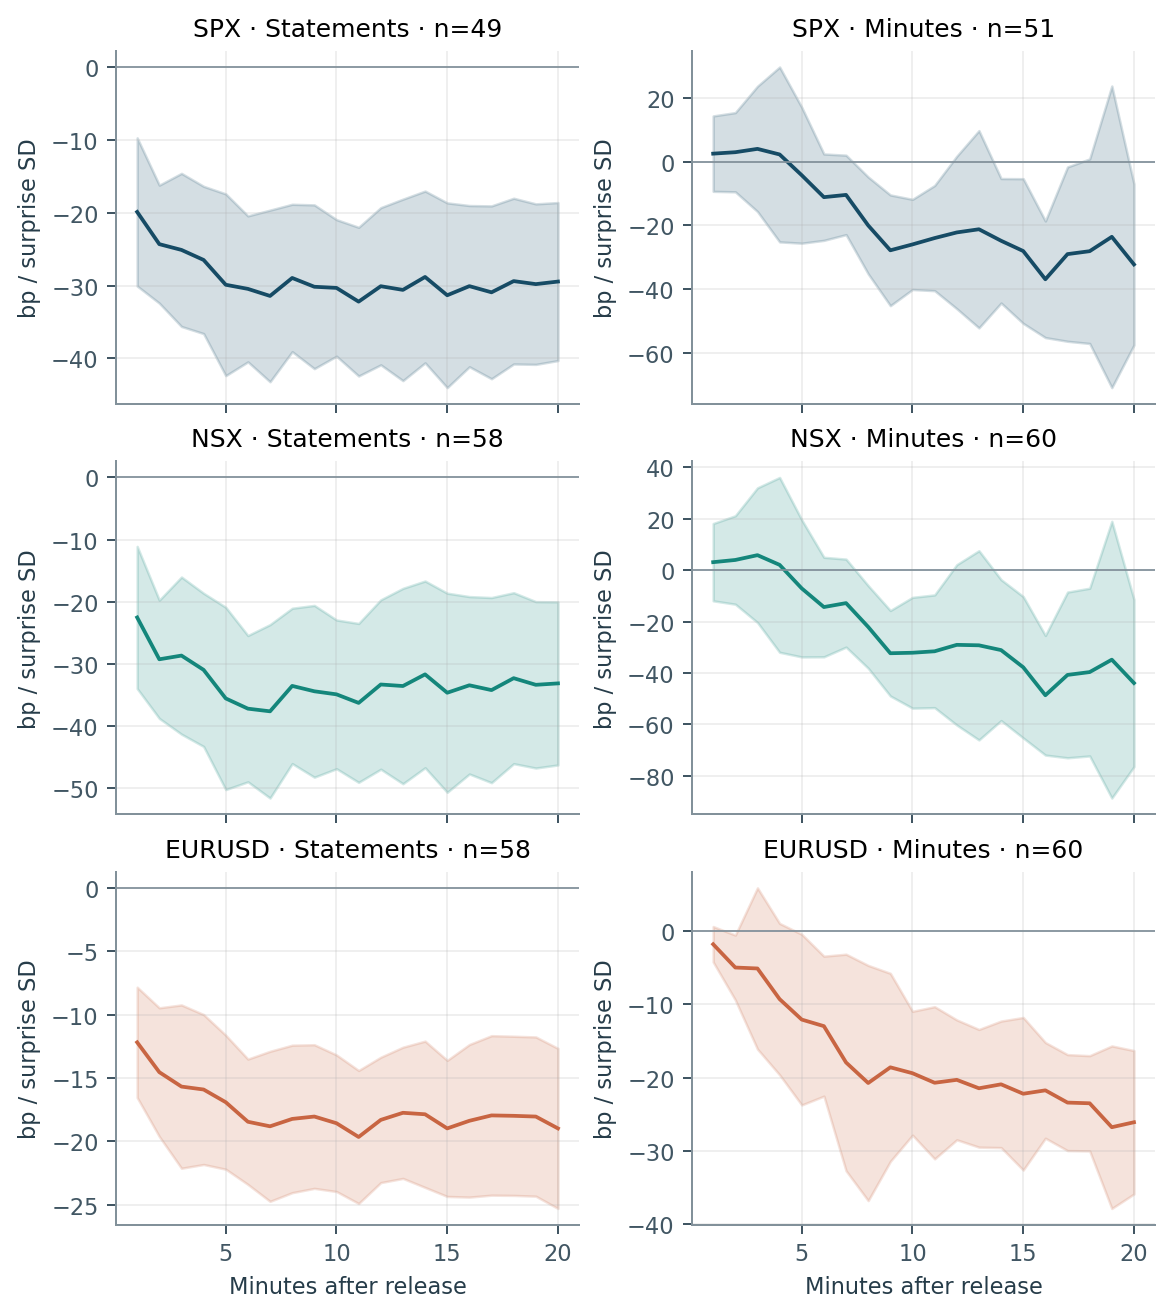

Figure 4. Pooled response curves with pointwise HC3 intervals. Panels have independent vertical scales. Asset and event-type comparisons are exploratory; the factor remains scaled to development statements.

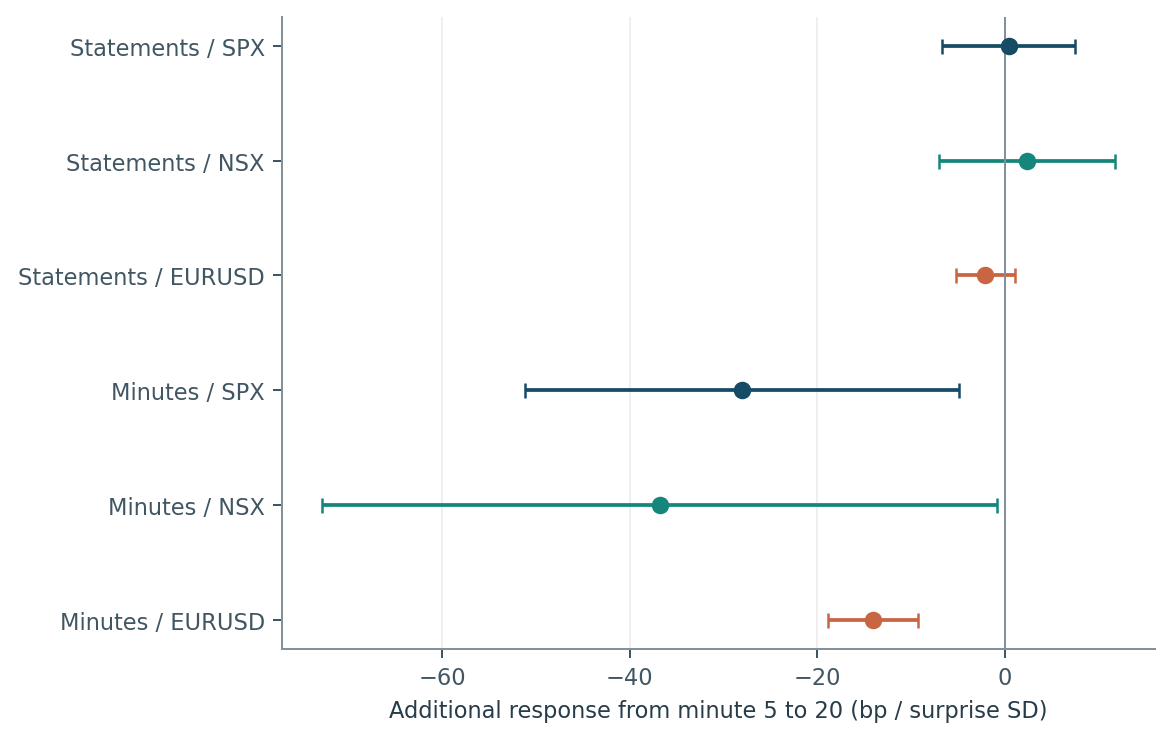

Figure 5. The additional 5-to-20-minute response and its 95% HC3 interval. An interval containing zero does not establish that adjustment is complete.

In [4]:
effects = pd.concat([table(f'effects-{p}.csv') for p in ['development','holdout','pooled']],ignore_index=True)
selected = effects.query("asset=='SPX' and measure in ['cumulative_20','late_5_20']").copy()
selected['phase']=selected.phase.replace({'holdout':'later, post-audit'})
show_table(selected[['phase','event_type','measure','n','estimate','ci_low','ci_high']], 'Table N03.2. Primary response and additional 5-to-20-minute association.')
show_figure(4)
show_figure(5)

## What the response estimates say

The pooled statement slope reaches −29.46 bp per development surprise SD by minute 20; the additional 5-to-20-minute slope is +0.44 bp, with a 95% interval of −6.66 to +7.54. This supports an early response association without proving adjustment is complete. Pooled minutes releases show an additional −28.05 bp association over minutes 5–20, with interval −51.23 to −4.86. That extension is exploratory and is not evidence that the same structural mechanism governs statements and minutes.

The later-period statement slope is smaller in magnitude than the development slope, with broad intervals. These intervals are not a formal test of equality across periods. The primary development and pooled statement samples also fail the coverage gate, so their estimates describe accepted windows rather than a certified representative event population.

The simultaneous band covers 20 horizons within one asset/type/sample family. It does not correct the entire project for all assets, types, specifications and exploratory comparisons. The PCA is treated as a frozen regressor: reported intervals are conditional on its estimated training loadings and do not propagate first-stage factor-estimation uncertainty.

event_type,asset,n,median_rv_ratio,ci_low,ci_high
Minutes,EURUSD,60,6.860,4.637,8.887
Minutes,NSX,60,2.907,1.554,5.471
Minutes,SPX,51,2.946,1.896,8.773
Statements,EURUSD,58,52.532,29.346,71.283
Statements,NSX,58,9.800,6.163,14.778
Statements,SPX,48,10.581,5.113,19.809


Equation (14). Realised variance in an event window.
RV_{e,a}=\sum_{t=0}^{19}r_{e,a,t}^{\,2}
Measured in squared basis points and compared with the selected matched weekday.

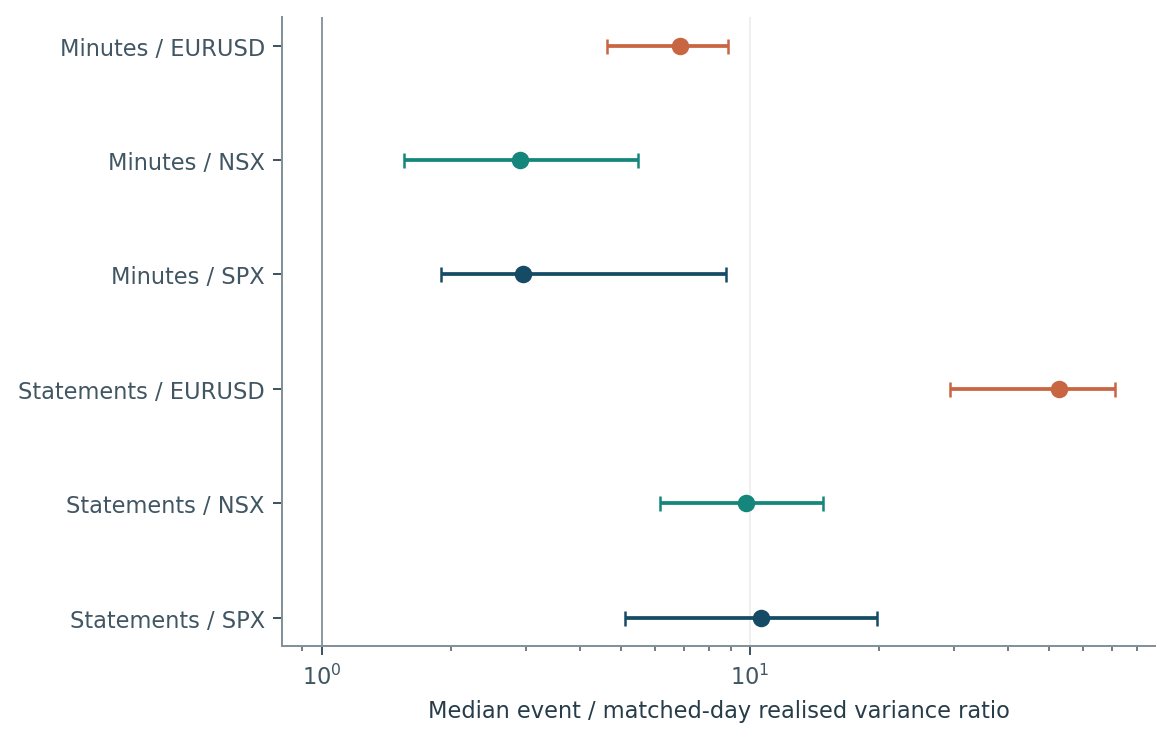

Figure 7. First-20-minute realised variance relative to the matched weekday. Intervals are event-pair bootstrap intervals; a variance increase measures activity rather than the fraction of information absorbed.

In [5]:
rv = table('realised-variance-summary.csv')
show_table(rv[['event_type','asset','n','median_rv_ratio','ci_low','ci_high']], 'Table N03.3. Event versus matched-day realised variance.')
equation(14)
show_figure(7)

## Milestone outcome

The price-response associations are reproducible from cached minute bars and a fixed surprise model. Larger event-window variance confirms unusual activity, not a measured proportion of information incorporated. Signed responses, lagged responses and variance are kept as separate quantities.